In [25]:
# Importamos todas las librerías necesarias
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# **1 - Exploración de los datos del dataset AirBnB Milan** 

## **1.1 - CARGA DEL DATASET**

In [2]:
# Download latest version
RAW_DATA_PATH = kagglehub.dataset_download("antoniokaggle/milan-airbnb-open-data-only-entire-apartments")

print("Path to dataset files:", RAW_DATA_PATH)

Path to dataset files: C:\Users\sandr\.cache\kagglehub\datasets\antoniokaggle\milan-airbnb-open-data-only-entire-apartments\versions\1


In [3]:
df_raw = pd.read_csv(Path(RAW_DATA_PATH) / "Airbnb_Milan.csv", index_col=0)
pd.set_option('display.max_columns', len(df_raw.columns)) # Para ver todas las columnas
pd.set_option('display.max_rows', 100)
df_raw

,id,host_id,host_location,host_response_time,host_response_rate,host_is_superhost,host_total_listings_count,host_has_profile_pic,host_identity_verified,neighbourhood_cleansed,zipcode,latitude,longitude,room_type,accommodates,bathrooms,bedrooms,beds,bed_type,daily_price,security_deposit,cleaning_fee,guests_included,extra_people,minimum_nights,availability_30,availability_60,availability_90,availability_365,number_of_reviews,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification,TV,WiFi,Air_Condition,Wheelchair_accessible,Kitchen,Breakfast,Elevator,Heating,Washer,Iron,Host_greets_you,Paid_parking_on_premises,Luggage_dropoff_allowed,Long_term_stays_allowed,Doorman,Pets_allowed,Smoking_allowed,Suitable_for_events,24_hour_check_in
1,73892,387110,1,1,57,0,3,1,1,1,20121,45.47015,9.19134,Entire home/apt,2,3,1,1,1,94,1,45,1,0,2,29,59,89,364,84,94,9,9,10,10,10,9,0,1,1,1,1,1,1,0,1,0,1,1,0,1,0,0,0,0,0,0,0,1,0
2,74169,268127,1,1,57,0,1,1,0,1,20121,45.47169,9.18412,Entire home/apt,4,3,1,1,1,125,31,30,1,0,2,0,0,9,284,3,100,10,10,10,10,10,9,0,0,0,0,1,1,1,0,1,0,1,1,1,1,0,0,0,0,0,0,0,0,0
3,77958,387110,1,1,57,0,3,1,1,1,20121,45.47117,9.19135,Entire home/apt,2,3,1,1,1,100,1,45,1,0,2,29,59,89,364,70,97,9,10,10,10,10,9,0,1,1,1,1,1,1,0,1,0,1,1,0,1,0,0,0,0,0,0,0,1,0
4,93025,499743,1,1,57,0,1,1,0,1,20121,45.47204,9.19640,Entire home/apt,3,3,1,2,1,120,48,57,2,40,2,10,40,70,160,57,97,10,10,10,10,10,10,0,1,0,0,1,1,1,0,1,0,1,1,0,1,0,1,1,0,0,1,0,0,0
5,132705,391011,1,1,57,1,2,1,0,1,20135,45.45934,9.20609,Entire home/apt,2,3,0,1,3,70,13,45,1,0,30,27,57,87,362,44,90,9,9,10,10,9,9,0,1,1,1,1,1,1,0,1,0,1,1,1,1,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9318,35954783,56584596,1,1,57,0,1,1,1,9,20124,45.48586,9.19706,Entire home/apt,2,3,1,1,1,80,1,1,1,0,1,1,1,1,1,1,100,10,10,10,10,10,10,0,1,0,0,1,1,1,0,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0
9319,36023503,271013325,1,1,57,0,1,1,0,9,20124,45.48170,9.18968,Entire home/apt,6,5,2,2,1,900,1,69,2,30,1,9,9,18,204,2,100,10,10,10,10,10,10,1,0,0,0,1,1,1,0,1,1,1,1,1,1,0,0,0,0,0,1,0,0,0
9320,36071908,271354203,1,0,57,0,1,1,0,9,20159,45.49807,9.18476,Entire home/apt,2,3,1,1,1,70,1,20,1,20,1,30,60,90,365,3,100,9,10,10,10,9,10,0,1,0,0,1,1,1,0,1,1,0,1,1,0,1,0,0,0,0,0,0,0,0
9321,36305676,171239896,1,1,40,0,3,1,0,9,20158,45.50107,9.18210,Entire home/apt,4,3,1,2,1,65,1,1,1,0,1,29,59,89,364,1,100,10,10,10,10,10,10,0,1,0,0,1,1,1,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0


## **1.2 - Detección de datos duplicados y/o nulos**

In [4]:
# Verificar si hay valores nulos en el DataFrame
df_raw.isnull().sum().sort_values(ascending=False)

id                                  0
host_id                             0
host_location                       0
host_response_time                  0
host_response_rate                  0
host_is_superhost                   0
host_total_listings_count           0
host_has_profile_pic                0
host_identity_verified              0
neighbourhood_cleansed              0
zipcode                             0
latitude                            0
longitude                           0
room_type                           0
accommodates                        0
bathrooms                           0
bedrooms                            0
beds                                0
bed_type                            0
daily_price                         0
security_deposit                    0
cleaning_fee                        0
guests_included                     0
extra_people                        0
minimum_nights                      0
availability_30                     0
availability

No nulos en ninguna columna

In [5]:
df_raw.isnull().sum(axis=None)

np.int64(0)

Chequeamos si hay duplicados: nos fijamos por el `id`

In [6]:
df_raw["id"].nunique() == len(df_raw)

True

## 1.3 - Descripción del dataset: Milan Airbnb

El dataset contiene información sobre alojamientos publicados en Airbnb en la ciudad de Milán (Italia), considerando únicamente propiedades que se alquilan completas.

El objetivo del problema de regresión es **predecir el precio por noche (`daily_price`)** a partir de las características de los alojamientos, sus anfitriones, ubicación, disponibilidad y evaluaciones.

### 1) Identificación e información del anfitrión

- **`id`**: Identificador único del apartamento.
- **`host_id`**: Identificador único del anfitrión.
- **`host_location`**: Indica si el anfitrión reside en Italia. `1 = Italia`, `0 = fuera de Italia`.
- **`host_response_time`**: Indica la rapidez de respuesta del anfitrión. `1 = rápida`, `0 = lenta`.
- **`host_response_rate`**: Porcentaje de consultas respondidas por el anfitrión.
- **`host_is_superhost`**: Indica si el anfitrión tiene la categoría Superhost. `1 = sí`, `0 = no`.
- **`host_total_listings_count`**: Cantidad total de propiedades publicadas por el anfitrión.
- **`host_has_profile_pic`**: Indica si el anfitrión tiene una foto de perfil. `1 = sí`, `0 = no`.
- **`host_identity_verified`**: Indica si Airbnb verificó la identidad del anfitrión. `1 = sí`, `0 = no`.

### 2) Ubicación del alojamiento

- **`neighbourhood_cleansed`**: Barrio o zona de la ciudad donde se encuentra el alojamiento, según la clasificación normalizada de Airbnb.
- **`zipcode`**: Código postal del alojamiento.
- **`latitude`**: Latitud geográfica del alojamiento.
- **`longitude`**: Longitud geográfica del alojamiento.

### 3) Características del alojamiento

- **`room_type`**: Tipo de alojamiento ofrecido. En este dataset se consideran únicamente apartamentos o viviendas completas.
- **`accommodates`**: Cantidad máxima de huéspedes que puede alojar la propiedad.
- **`bathrooms`**: Cantidad de baños del alojamiento.
- **`bedrooms`**: Cantidad de dormitorios del alojamiento.
- **`beds`**: Cantidad de camas disponibles.
- **`bed_type`**: Tipo de cama ofrecida, representado mediante categorías.

### 4) Precios y condiciones de reserva

- **`daily_price`**: Precio de alquiler por noche. **Variable objetivo de la regresión.**
- **`security_deposit`**: Depósito de garantía solicitado por el anfitrión.
- **`cleaning_fee`**: Cargo adicional por limpieza del alojamiento.
- **`guests_included`**: Cantidad de huéspedes incluidos en el precio base.
- **`extra_people`**: Cargo adicional por cada huésped extra.
- **`minimum_nights`**: Cantidad mínima de noches exigida para reservar el alojamiento.

### 5) Disponibilidad

- **`availability_30`**: Cantidad de días disponibles para reservar durante los próximos 30 días.
- **`availability_60`**: Cantidad de días disponibles para reservar durante los próximos 60 días.
- **`availability_90`**: Cantidad de días disponibles para reservar durante los próximos 90 días.
- **`availability_365`**: Cantidad de días disponibles para reservar durante los próximos 365 días.

### 6) Reseñas y evaluaciones

- **`number_of_reviews`**: Cantidad total de reseñas recibidas por el alojamiento.
- **`review_scores_rating`**: Puntuación general del alojamiento otorgada por los huéspedes (escala de 0 a 100).
- **`review_scores_accuracy`**: Puntuación sobre qué tan precisa es la descripción del alojamiento (0 a 10).
- **`review_scores_cleanliness`**: Puntuación de limpieza del alojamiento (0 a 10).
- **`review_scores_checkin`**: Puntuación del proceso de ingreso o check-in (0 a 10).
- **`review_scores_communication`**: Puntuación de la comunicación con el anfitrión (0 a 10).
- **`review_scores_location`**: Puntuación de la ubicación del alojamiento (0 a 10).
- **`review_scores_value`**: Puntuación de la relación calidad-precio del alojamiento (0 a 10).

### 7) Políticas y condiciones adicionales

- **`instant_bookable`**: Indica si el alojamiento permite realizar reservas instantáneas sin aprobación previa del anfitrión.
- **`cancellation_policy`**: Tipo de política de cancelación establecida por el anfitrión.
- **`require_guest_profile_picture`**: Indica si se exige que el huésped tenga una foto de perfil.
- **`require_guest_phone_verification`**: Indica si se exige que el huésped tenga su número telefónico verificado.

### 8) Servicios y comodidades

Las siguientes variables son binarias: `1 = disponible/permitido`, `0 = no disponible/no permitido`.

- **`TV`**: Disponibilidad de televisión.
- **`WiFi`**: Disponibilidad de conexión inalámbrica a Internet.
- **`Air_Condition`**: Disponibilidad de aire acondicionado.
- **`Wheelchair_accessible`**: Accesibilidad para personas que utilizan silla de ruedas.
- **`Kitchen`**: Disponibilidad de cocina.
- **`Breakfast`**: Desayuno incluido u ofrecido.
- **`Elevator`**: Disponibilidad de ascensor.
- **`Heating`**: Disponibilidad de calefacción.
- **`Washer`**: Disponibilidad de lavarropas.
- **`Iron`**: Disponibilidad de plancha.
- **`Host_greets_you`**: Indica si el anfitrión recibe personalmente a los huéspedes.
- **`Paid_parking_on_premises`**: Disponibilidad de estacionamiento pago dentro de la propiedad.
- **`Luggage_dropoff_allowed`**: Posibilidad de dejar el equipaje antes del check-in o después del check-out.
- **`Long_term_stays_allowed`**: Indica si se permiten estadías prolongadas.
- **`Doorman`**: Disponibilidad de portero o servicio de recepción.
- **`Pets_allowed`**: Indica si se permiten mascotas.
- **`Smoking_allowed`**: Indica si se permite fumar.
- **`Suitable_for_events`**: Indica si el alojamiento permite organizar eventos.
- **`24_hour_check_in`**: Disponibilidad de ingreso al alojamiento durante las 24 horas.

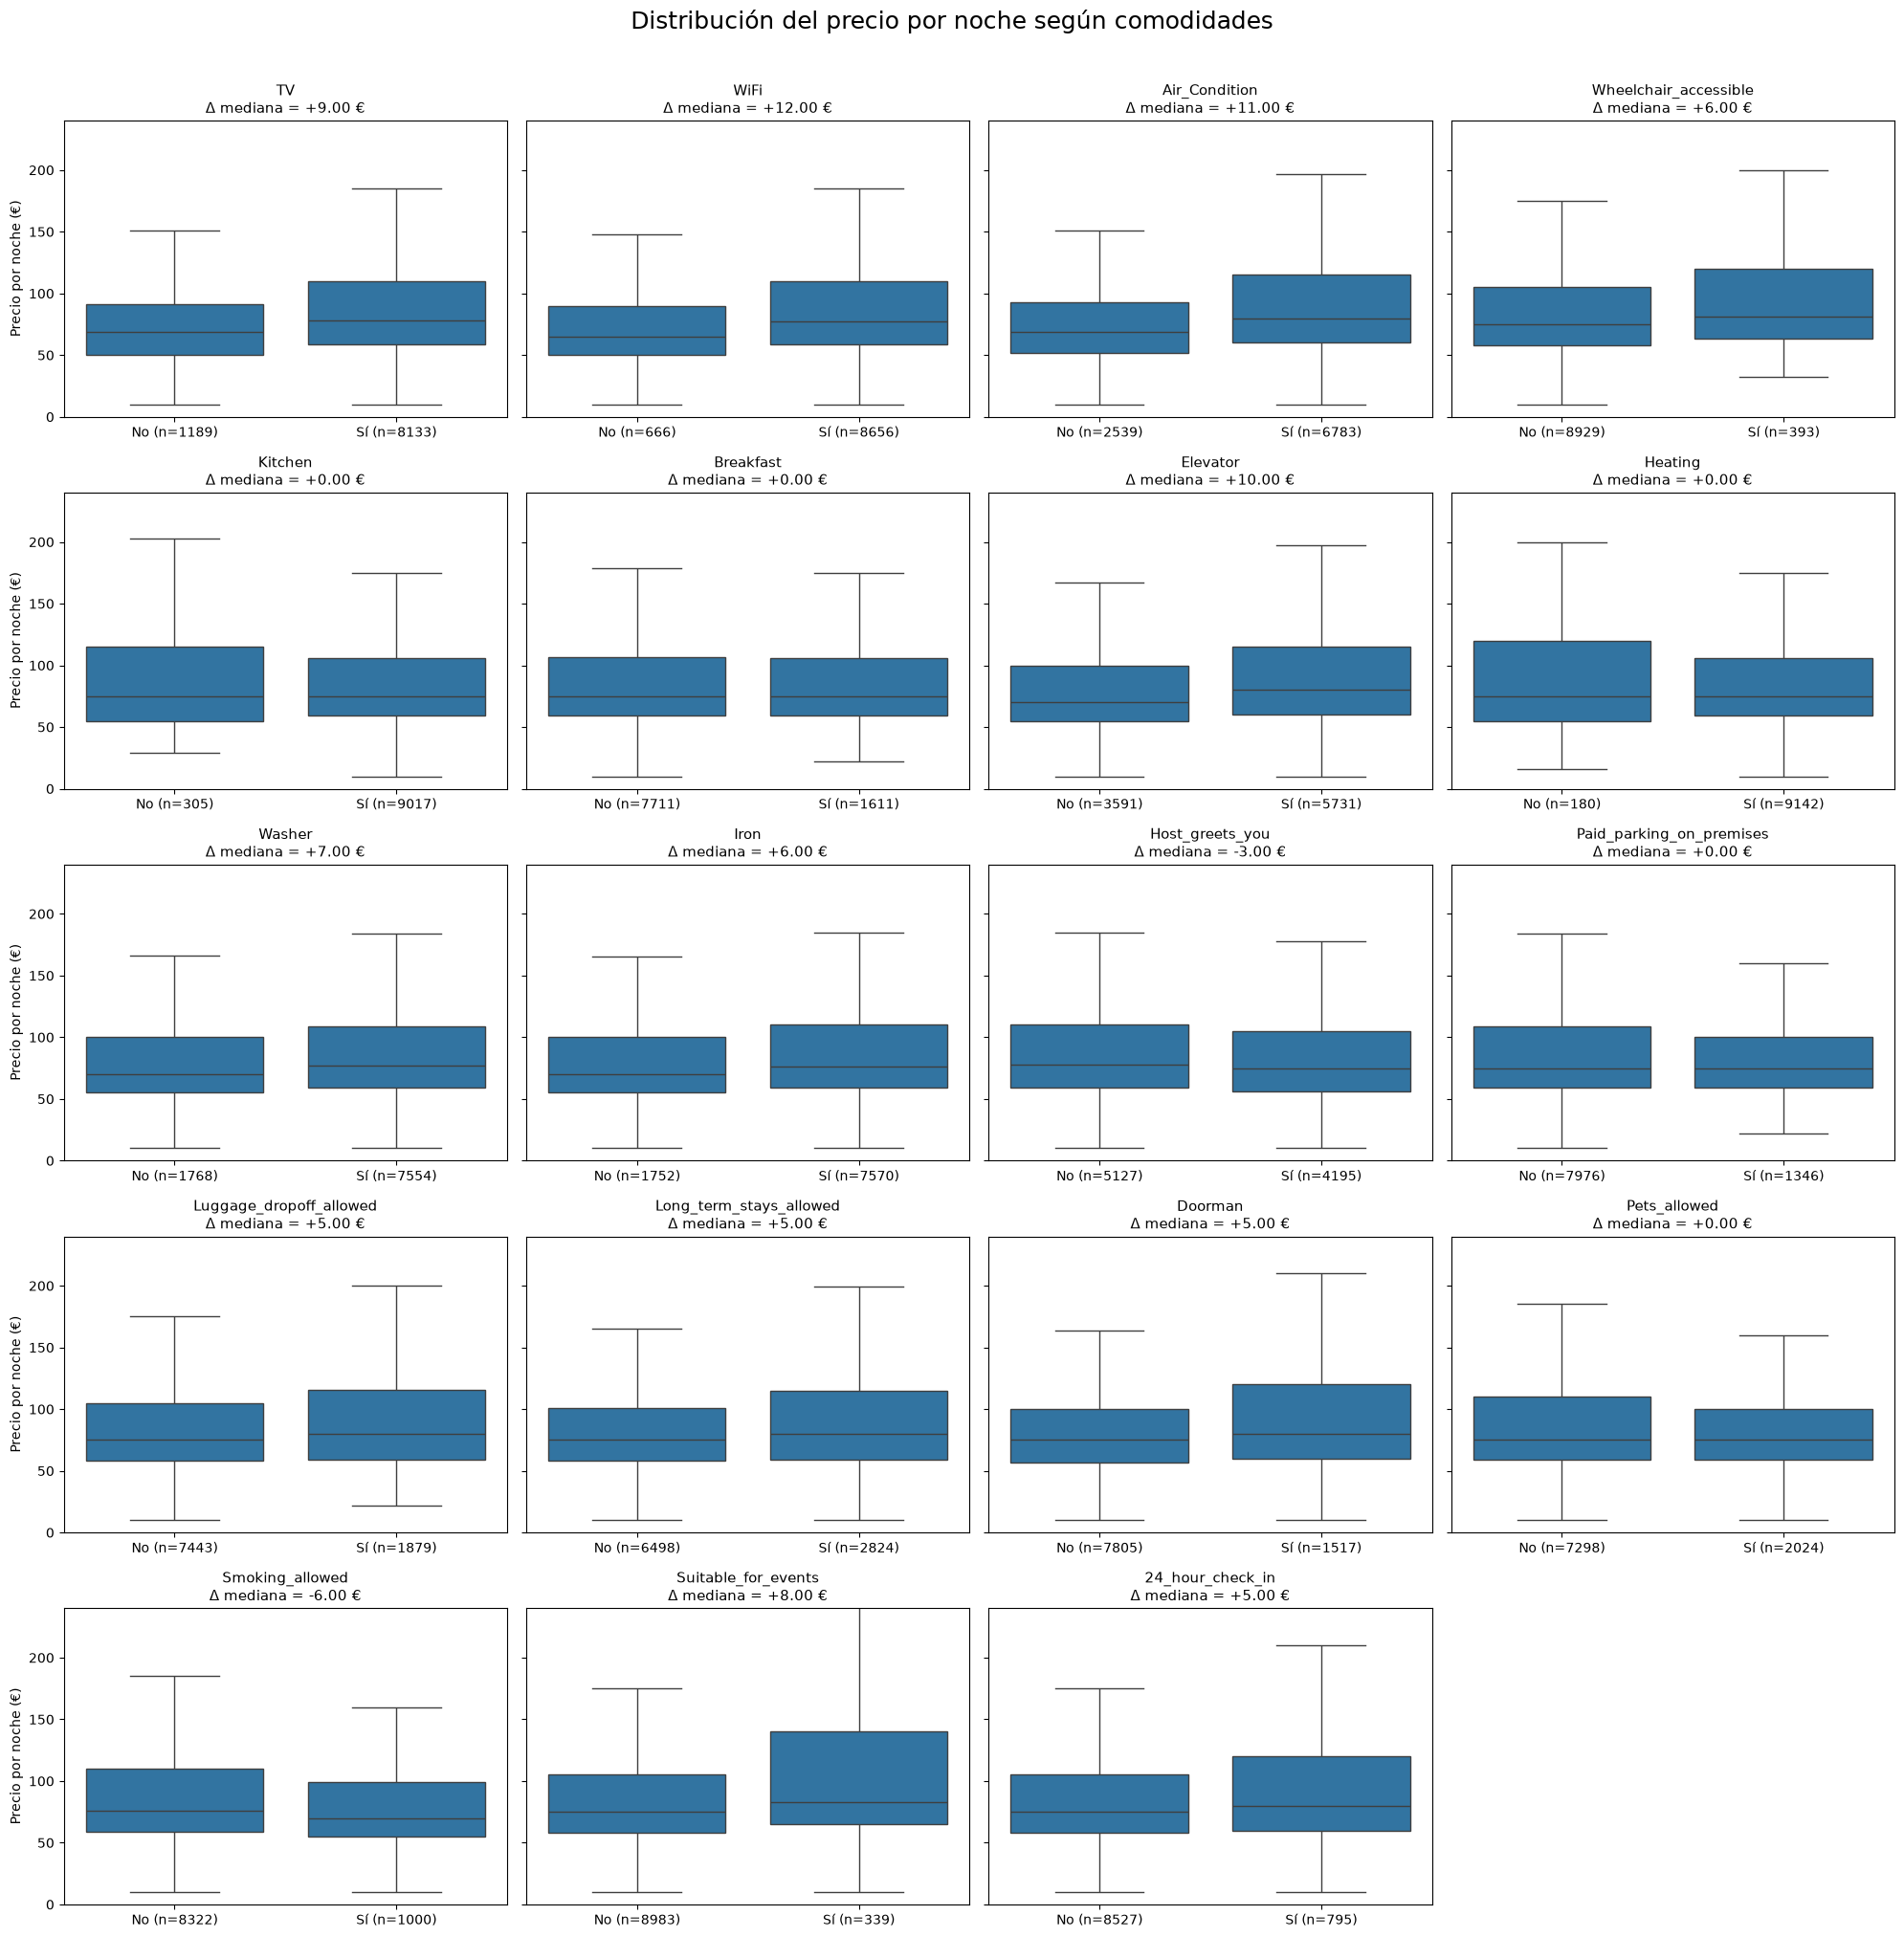

In [36]:
amenities = [
    "TV",
    "WiFi",
    "Air_Condition",
    "Wheelchair_accessible",
    "Kitchen",
    "Breakfast",
    "Elevator",
    "Heating",
    "Washer",
    "Iron",
    "Host_greets_you",
    "Paid_parking_on_premises",
    "Luggage_dropoff_allowed",
    "Long_term_stays_allowed",
    "Doorman",
    "Pets_allowed",
    "Smoking_allowed",
    "Suitable_for_events",
    "24_hour_check_in",
]

# Configuración de la grilla
n_cols = 4
n_rows = int(np.ceil(len(amenities) / n_cols))

fig, axes = plt.subplots( n_rows, n_cols, figsize=(20, 20), sharey=True)

axes = axes.flatten()

for ax, col in zip(axes, amenities):

    sns.boxplot(
        data=df_raw,
        x=col,
        y="daily_price",
        order=[0, 1],
        showfliers=False,
        ax=ax
    )

    # Diferencia de medianas: con comodidad - sin comodidad
    medianas = df_raw.groupby(col)["daily_price"].median()
    diferencia = medianas.get(1, np.nan) - medianas.get(0, np.nan)

    # Cantidad de observaciones por grupo
    counts = df_raw[col].value_counts()

    ax.set_title(
        f"{col}\nΔ mediana = {diferencia:+.2f} €",
        fontsize=11
    )

    ax.set_xticks([0, 1])
    ax.set_xticklabels([
        f"No (n={counts.get(0, 0)})",
        f"Sí (n={counts.get(1, 0)})"
    ])

    ax.set_xlabel("")
    ax.set_ylabel("Precio por noche (€)")

    # Mismo rango para todos los gráficos
    ax.set_ylim(0, df_raw["daily_price"].quantile(0.95))

# Eliminar ejes sobrantes
for ax in axes[len(amenities):]:
    ax.remove()

fig.suptitle(
    "Distribución del precio por noche según comodidades",
    fontsize=18,
    y=1.01
)

plt.tight_layout()
plt.show()



### 1.4 Selección de variables

Se seleccionaron **15 variables predictoras** para estimar el precio por noche (`daily_price`) de los alojamientos.

La selección busca representar distintos factores que podrían influir en el precio:

- **Características del alojamiento:** `accommodates`, `bedrooms` y `bathrooms`, que describen su capacidad y tamaño.
- **Ubicación geográfica:** `latitude`, `longitude` y `neighbourhood_cleansed`, dado que la localización puede influir significativamente en el precio.
- **Costos y condiciones de reserva:** `cleaning_fee` y `minimum_nights`, que describen cargos adicionales y restricciones de estadía.
- **Anfitrión y reputación:** `host_is_superhost`, `host_total_listings_count`, `review_scores_rating` y `number_of_reviews`, que representan la experiencia del anfitrión y las valoraciones de los huéspedes.
- **Comodidades:** `WiFi`, `Air_Condition` y `Elevator`, seleccionadas a partir del análisis exploratorio, ya que presentan diferencias de al menos 10 € entre las medianas del precio de los alojamientos que disponen de estas comodidades y los que no.

Se priorizaron variables interpretables y potencialmente relevantes para la predicción. Su aporte predictivo será evaluado posteriormente durante el modelado, considerando posibles correlaciones y redundancias entre las variables.



In [49]:

FEATURES = [
    # Características del alojamiento
    "accommodates",
    "bedrooms",
    "bathrooms",

    # Ubicación geográfica
    "latitude",
    "longitude",
    "neighbourhood_cleansed",

    # Costos y condiciones de reserva
    "cleaning_fee",
    "minimum_nights",

    # Anfitrión y reputación
    "host_is_superhost",
    "host_total_listings_count",
    "review_scores_rating",
    "number_of_reviews",

    # Comodidades
    "WiFi",
    "Air_Condition",
    "Elevator",
]

TARGET = "daily_price"

df = df_raw[FEATURES + [TARGET]].copy()


### Análisis exploratorio

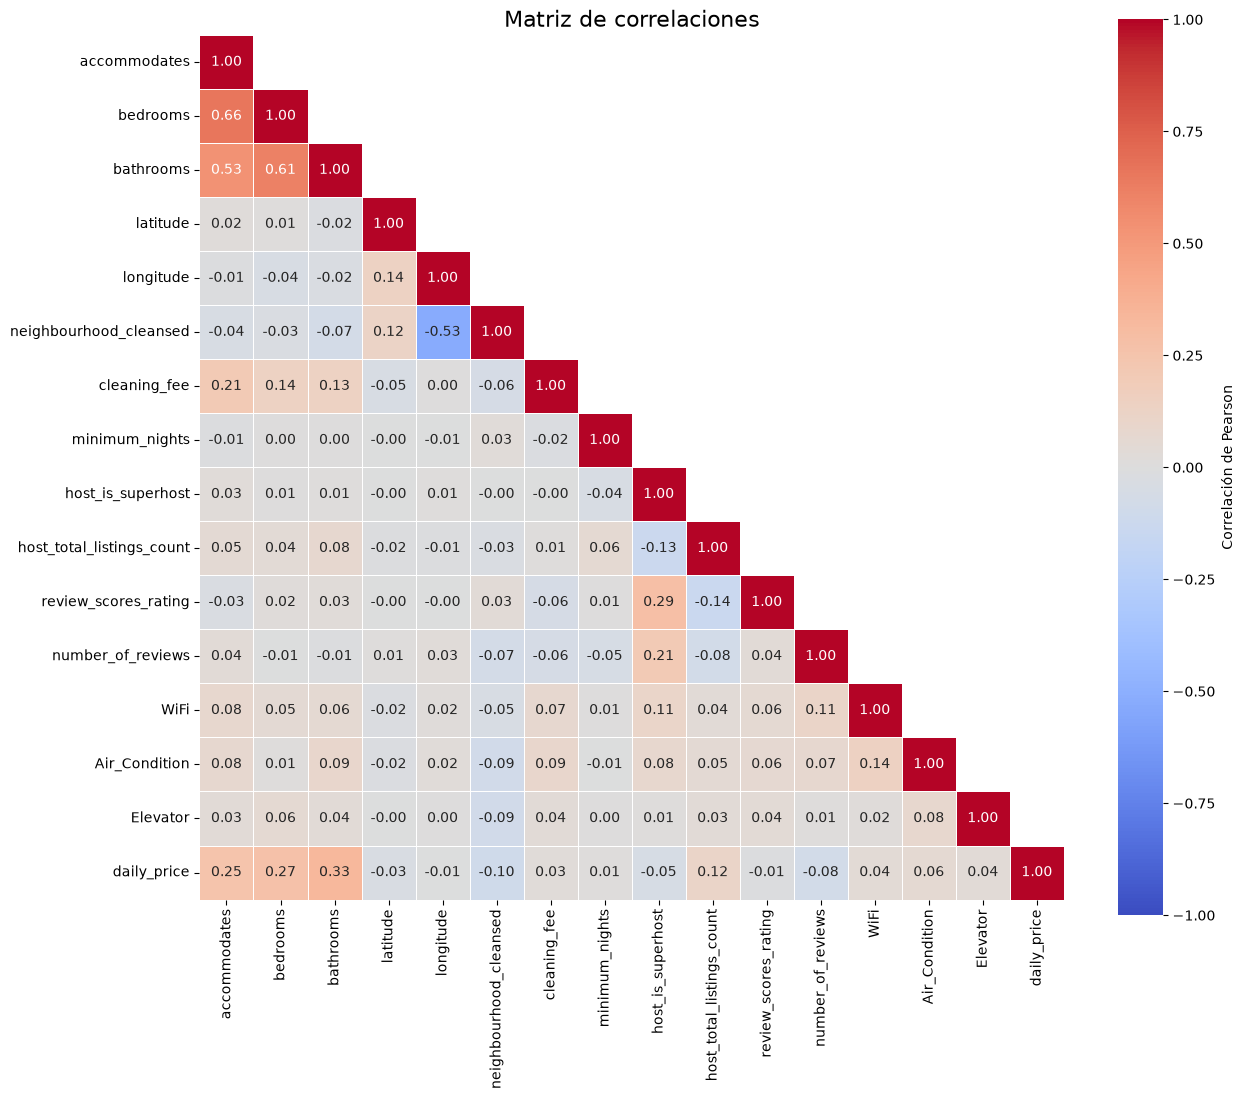

In [50]:
# Matriz de correlaciones de Pearson
corr = df.corr(method="pearson")

# Ocultar triángulo superior
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(13, 11))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Correlación de Pearson"}
)

plt.title("Matriz de correlaciones", fontsize=16)
plt.tight_layout()
plt.show()


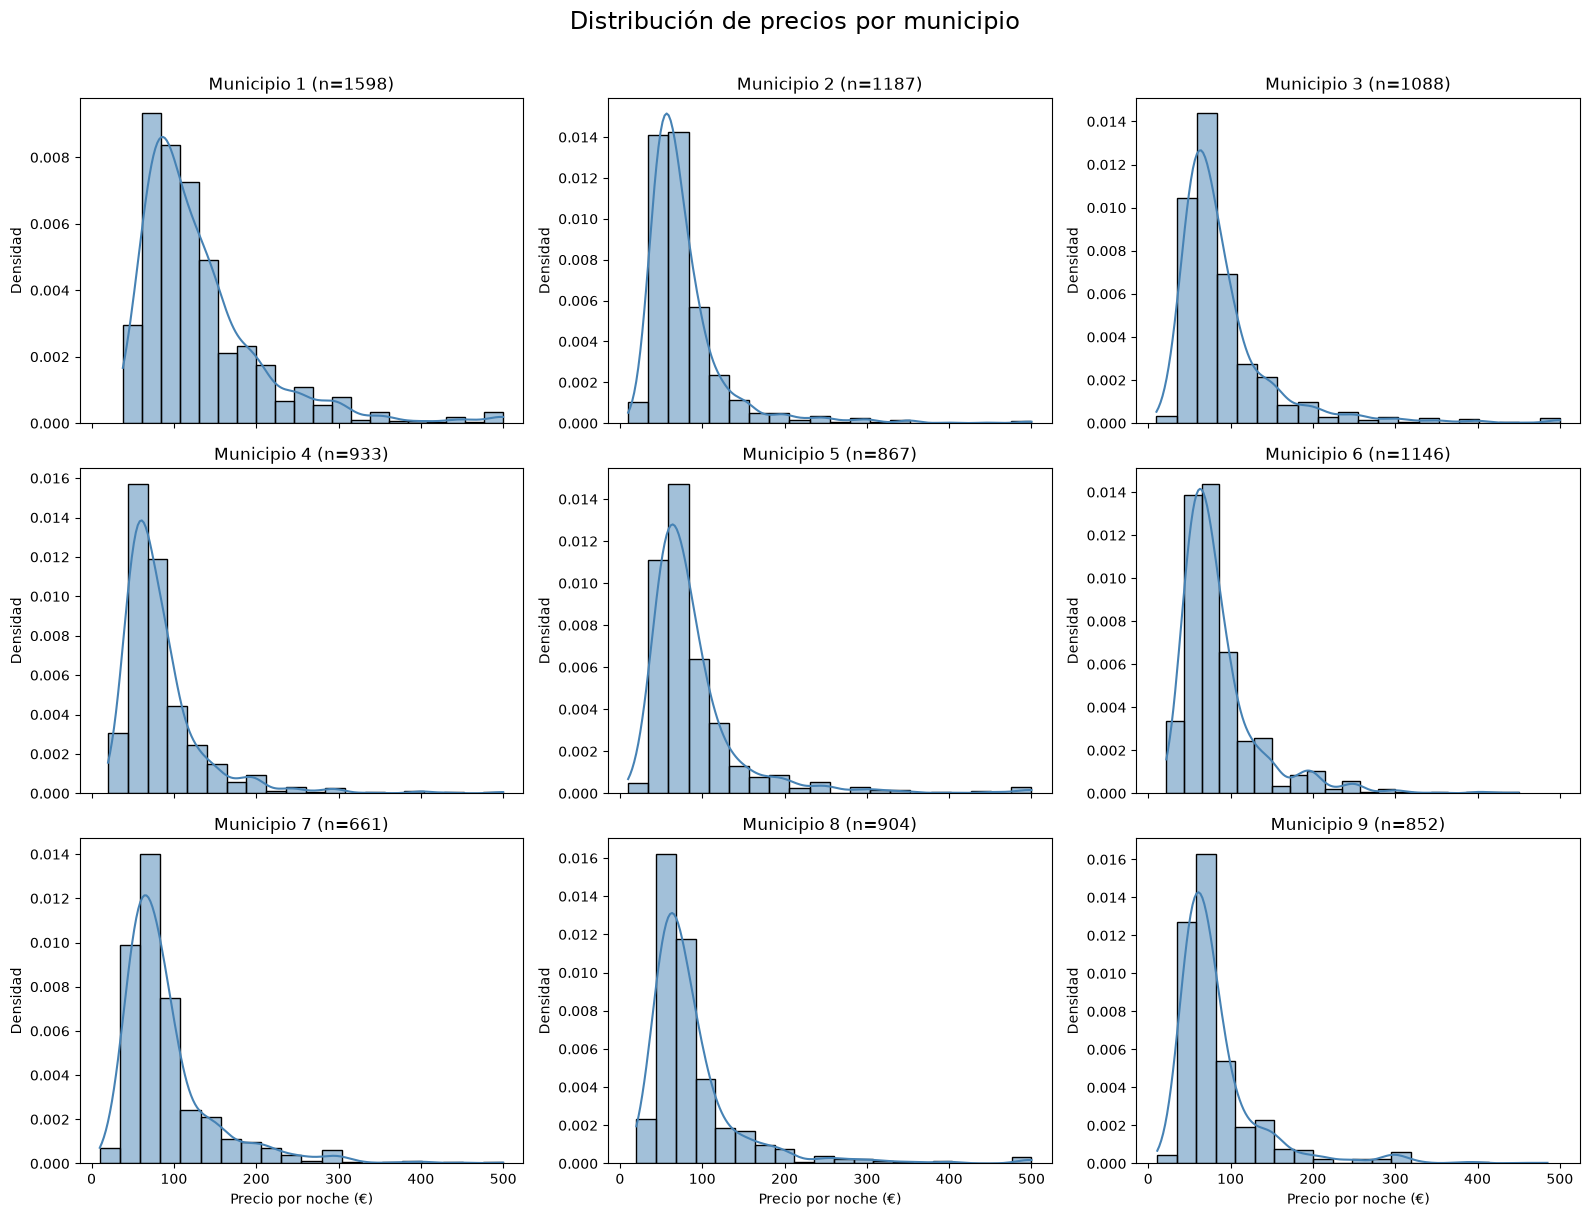

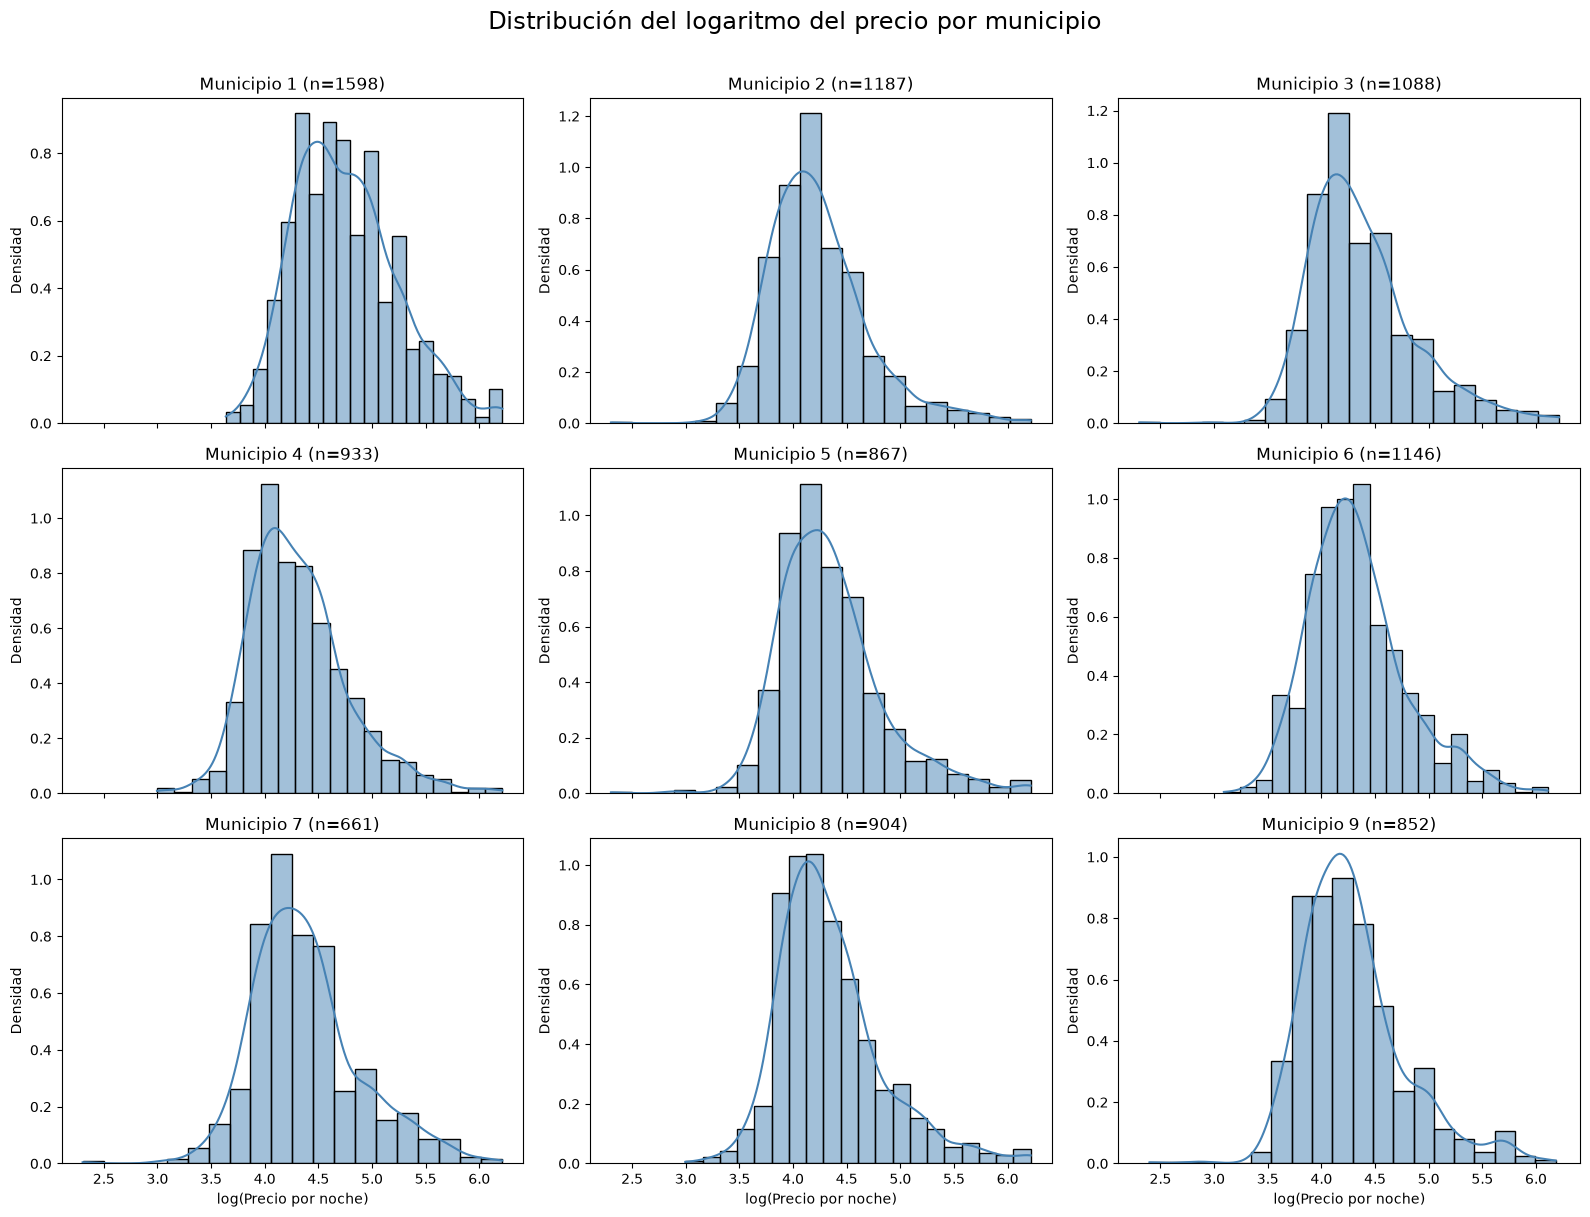

In [51]:
from math import ceil

# Preparación de los datos
data = df[
    ["neighbourhood_cleansed", "daily_price"]
].dropna().copy()

# El logaritmo requiere precios positivos
data = data[data["daily_price"] > 0]

# Excluir el 1% de precios más altos solo para visualizar
limite = data["daily_price"].quantile(0.99)
data = data[data["daily_price"] <= limite].copy()

# Transformación logarítmica
data["log_daily_price"] = np.log(data["daily_price"])

# Municipios
municipios = sorted(data["neighbourhood_cleansed"].unique())


def plot_histogramas_por_municipio(columna, titulo, xlabel):
    n_cols = 3
    n_rows = ceil(len(municipios) / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(16, 4 * n_rows),
        sharex=True
    )

    axes = np.array(axes).flatten()

    for ax, municipio in zip(axes, municipios):
        subset = data[
            data["neighbourhood_cleansed"] == municipio
        ]

        sns.histplot(
            data=subset,
            x=columna,
            bins=20,
            kde=True,
            stat="density",
            color="steelblue",
            ax=ax
        )

        ax.set_title(
            f"Municipio {municipio} (n={len(subset)})"
        )
        ax.set_xlabel(xlabel)
        ax.set_ylabel("Densidad")

    # Eliminar ejes sobrantes
    for ax in axes[len(municipios):]:
        ax.remove()

    fig.suptitle(titulo, fontsize=17, y=1.01)
    plt.tight_layout()
    plt.show()


# Figura 1: precios originales
plot_histogramas_por_municipio(
    "daily_price",
    "Distribución de precios por municipio",
    "Precio por noche (€)"
)

# Figura 2: logaritmo de los precios
plot_histogramas_por_municipio(
    "log_daily_price",
    "Distribución del logaritmo del precio por municipio",
    "log(Precio por noche)"
)


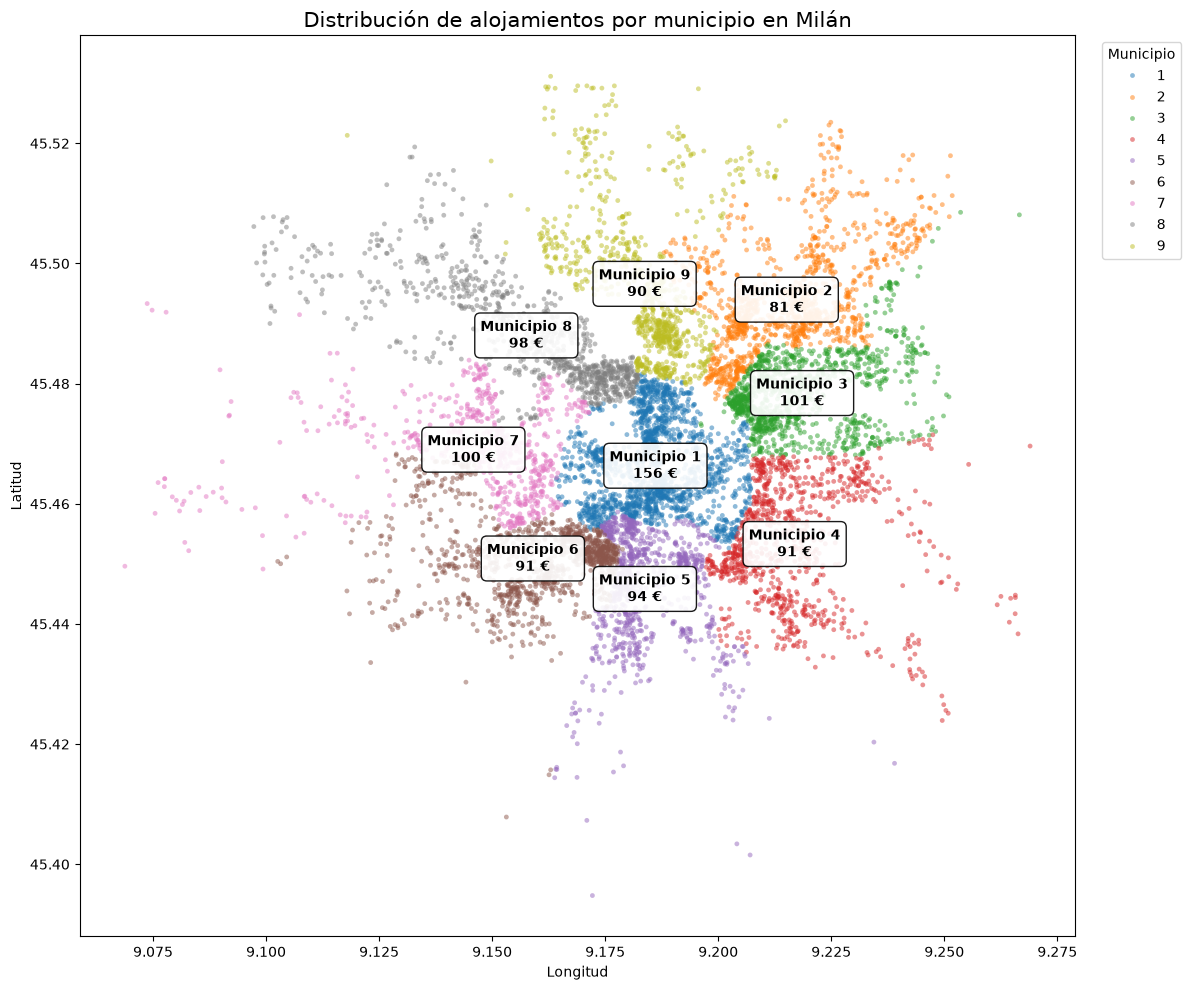

In [42]:

import matplotlib.pyplot as plt
import seaborn as sns

data = df[
    ["latitude", "longitude", "neighbourhood_cleansed", "daily_price"]
].dropna().copy()

# Convertir municipios a categorías
data["municipio"] = data["neighbourhood_cleansed"].astype(str)

# Estadísticas por municipio
municipios = (
    data.groupby("municipio")
    .agg(
        latitude=("latitude", "mean"),
        longitude=("longitude", "mean"),
        precio_medio=("daily_price", "mean"),
    )
    .reset_index()
)

# Gráfico
fig, ax = plt.subplots(figsize=(12, 10))

sns.scatterplot(
    data=data,
    x="longitude",
    y="latitude",
    hue="municipio",
    palette="tab10",
    s=12,
    alpha=0.5,
    linewidth=0,
    ax=ax,
)

# Etiquetas con municipio y precio mediano
for _, row in municipios.iterrows():
    ax.annotate(
        f"Municipio {row['municipio']}\n"
        f"{row['precio_medio']:.0f} €",
        xy=(row["longitude"], row["latitude"]),
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white",
            edgecolor="black",
            alpha=0.9,
        ),
    )

ax.set_title(
    "Distribución de alojamientos por municipio en Milán",
    fontsize=15,
)
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

ax.legend(
    title="Municipio",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()
plt.show()


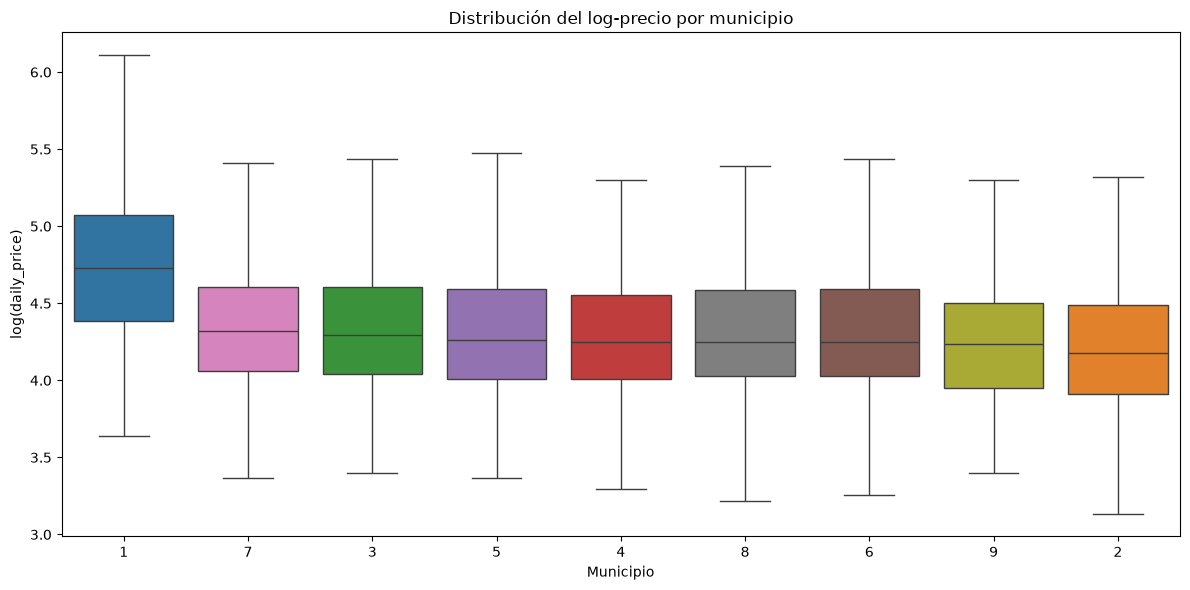

In [ ]:
# Preparación
data = df[
    ["latitude", "longitude", "neighbourhood_cleansed", "daily_price"]
].dropna().copy()

data = data[data["daily_price"] > 0]
data["log_daily_price"] = np.log(data["daily_price"])

# Ordenar municipios según el log-precio mediano
orden = (
    data.groupby("neighbourhood_cleansed")["log_daily_price"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=data,
    x="neighbourhood_cleansed",
    y="log_daily_price",
    order=orden,
    hue="neighbourhood_cleansed",
    palette="tab10",
    showfliers=False,
    legend=False,
)

plt.title("Distribución del log-precio por municipio")
plt.xlabel("Municipio")
plt.ylabel("log(daily_price)")
plt.tight_layout()
plt.show()
